#Phase 1: Libraries & (Data Preprocessing)

In [ ]:
import os, re, time, torch
import pandas as pd
import numpy as np
from tqdm import tqdm
import huggingface_hub
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, GRU, Dense, Dropout
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

dataset_path = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/WELFake_Dataset.csv'
save_dir = os.path.dirname(dataset_path)

print("1. Loading dataset from NEW Google Drive path...")
df = pd.read_csv(dataset_path).dropna(subset=['text', 'label'])

def clean_text(text):
    if not isinstance(text, str): return ""
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'[^\w\s]', '', text)
    return text.lower()

print("2. Cleaning text data... (Please wait a moment)")
tqdm.pandas(desc="Cleaning Progress")
df['text'] = df['text'].progress_apply(clean_text)
df = df[df['text'].str.strip() != '']
df['label'] = df['label'].astype(int)

print("\n3. Splitting and Saving Data (Train 80%, Val 10%, Test 10%)...")
X_train, X_temp, y_train, y_temp = train_test_split(df['text'], df['label'], test_size=0.20, stratify=df['label'], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

train_df = pd.DataFrame({'text': X_train, 'label': y_train})
val_df = pd.DataFrame({'text': X_val, 'label': y_val})
test_df = pd.DataFrame({'text': X_test, 'label': y_test})

train_df.to_csv(os.path.join(save_dir, 'train_80.csv'), index=False)
val_df.to_csv(os.path.join(save_dir, 'val_10.csv'), index=False)
test_df.to_csv(os.path.join(save_dir, 'test_10.csv'), index=False)
print("🎉 Phase 1 completed successfully!")

1. Loading dataset from NEW Google Drive path...
2. Cleaning text data... (Please wait a moment)


Cleaning Progress: 100%|██████████| 72095/72095 [00:30<00:00, 2391.86it/s]



3. Splitting and Saving Data (Train 80%, Val 10%, Test 10%)...
🎉 Phase 1 completed successfully!


#Phase 2 (Tier 1 - Random Forest)

In [ ]:
import os
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

dataset_path = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/WELFake_Dataset.csv'
save_dir = os.path.dirname(dataset_path)

print("1. Loading saved splits...")
train_df = pd.read_csv(os.path.join(save_dir, 'train_80.csv')).dropna()
val_df = pd.read_csv(os.path.join(save_dir, 'val_10.csv')).dropna()

X_train_raw, y_train = train_df['text'].astype(str), train_df['label'].astype(int)
X_val_raw, y_val = val_df['text'].astype(str), val_df['label'].astype(int)

print("2. Training Random Forest Model...")
global tfidf, rf_model
tfidf = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_val_tfidf = tfidf.transform(X_val_raw)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)

import joblib
# Save the TF-IDF vectorizer and Random Forest model to the save_dir
joblib.dump(tfidf, os.path.join(save_dir, 'tfidf_vectorizer.pkl'))
joblib.dump(rf_model, os.path.join(save_dir, 'random_forest_model.pkl'))
print("Model and Vectorizer saved successfully to Google Drive!")

rf_acc = accuracy_score(y_val, rf_model.predict(X_val_tfidf))
print(f"\n🌲 Phase 2 Completed! Random Forest Accuracy: {rf_acc * 100:.2f}%")

1. Loading saved splits...
2. Training Random Forest Model...
Model and Vectorizer saved successfully to Google Drive!

🌲 Phase 2 Completed! Random Forest Accuracy: 95.55%


#Phase 3 (Tier 2 - Bi-LSTM & GRU)

In [ ]:
import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, GRU, Dense, Dropout
from sklearn.metrics import accuracy_score

dataset_path = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/WELFake_Dataset.csv'
save_dir = os.path.dirname(dataset_path)

train_df = pd.read_csv(os.path.join(save_dir, 'train_80.csv')).dropna()
val_df = pd.read_csv(os.path.join(save_dir, 'val_10.csv')).dropna()

X_train_raw, y_train = train_df['text'].astype(str), train_df['label'].astype(int)
X_val_raw, y_val = val_df['text'].astype(str), val_df['label'].astype(int)

print("1. Tokenizing and Padding for Deep Learning...")
global keras_tokenizer
keras_tokenizer = Tokenizer(num_words=25000, oov_token="<OOV>")
keras_tokenizer.fit_on_texts(X_train_raw)
X_train_seq = pad_sequences(keras_tokenizer.texts_to_sequences(X_train_raw), maxlen=300, padding='post', truncating='post')
X_val_seq = pad_sequences(keras_tokenizer.texts_to_sequences(X_val_raw), maxlen=300, padding='post', truncating='post')

print("\n2. Training Bi-LSTM Model...")
global bilstm_model
bilstm_model = Sequential([
    Embedding(25000, 100), Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3), Dense(32, activation='relu'), Dense(1, activation='sigmoid')
])
bilstm_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
bilstm_model.fit(X_train_seq, y_train, batch_size=128, epochs=3, validation_data=(X_val_seq, y_val), verbose=1)
bilstm_acc = accuracy_score(y_val, (bilstm_model.predict(X_val_seq, verbose=0) > 0.5).astype(int))

print("\n3. Training GRU Model...")
global gru_model
gru_model = Sequential([
    Embedding(25000, 100), GRU(64, return_sequences=False),
    Dropout(0.3), Dense(32, activation='relu'), Dense(1, activation='sigmoid')
])
gru_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
gru_model.fit(X_train_seq, y_train, batch_size=128, epochs=3, validation_data=(X_val_seq, y_val), verbose=1)
gru_acc = accuracy_score(y_val, (gru_model.predict(X_val_seq, verbose=0) > 0.5).astype(int))

print(f"\n🚀 Phase 3 Completed! Bi-LSTM: {bilstm_acc * 100:.2f}%, GRU: {gru_acc * 100:.2f}%")

1. Tokenizing and Padding for Deep Learning...

2. Training Bi-LSTM Model...
Epoch 1/3
446/446 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.9377 - loss: 0.1645 - val_accuracy: 0.9676 - val_loss: 0.0916
Epoch 2/3
446/446 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.9802 - loss: 0.0602 - val_accuracy: 0.9700 - val_loss: 0.0858
Epoch 3/3
446/446 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.9897 - loss: 0.0326 - val_accuracy: 0.9766 - val_loss: 0.0735

3. Training GRU Model...
Epoch 1/3
446/446 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.7410 - loss: 0.5260 - val_accuracy: 0.8450 - val_loss: 0.3757
Epoch 2/3
446/446 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.8857 - loss: 0.2797 - val_accuracy: 0.9527 - val_loss: 0.1383
Epoch 3/3
446/446 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.9172 - loss: 0.2206 - val_accuracy: 0.9411 - val_loss: 0.1640

🚀 Phase 3 Completed! Bi-LSTM: 97.66%, GRU: 94.11%


#Phase 4 (Tier 3 - DistilBERT)

In [ ]:
import os
import pandas as pd
import torch
import huggingface_hub
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

os.environ.pop("HF_ENDPOINT", None)
huggingface_hub.constants.ENDPOINT = "https://huggingface.co"

print("1. Preparing data for DistilBERT...")
dataset_path = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/WELFake_Dataset.csv'
save_dir = os.path.dirname(dataset_path)

train_df = pd.read_csv(os.path.join(save_dir, 'train_80.csv')).dropna()
val_df = pd.read_csv(os.path.join(save_dir, 'val_10.csv')).dropna()

train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)

print("2. Loading Pre-trained Tokenizer & Model...")
model_name = "distilbert-base-uncased"
global tokenizer, model, trainer
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=256)

train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    return {'accuracy': accuracy_score(labels, preds), 'f1': f1, 'precision': precision, 'recall': recall}

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    warmup_steps=500,
    weight_decay=0.01,
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    fp16=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    compute_metrics=compute_metrics,
)

print("\n⏳ 3. Fine-Tuning Started... (This will take around 15-20 minutes on GPU)")
trainer.train()

print("\n" + "="*50)
print("🤖 FINAL DISTILBERT RESULTS 🤖")
eval_results = trainer.evaluate()
for key, value in eval_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
print("="*50)
print("🎉 Phase 4 completed! All models are now fully trained and ready.")

1. Preparing data for DistilBERT...
2. Loading Pre-trained Tokenizer & Model...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


🤖 FINAL DISTILBERT RESULTS 🤖


Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.009131,0.043398,2,0.986390,0.986600,0.987828,0.985375


eval_loss: 0.0434
eval_accuracy: 0.9864
eval_f1: 0.9866
eval_precision: 0.9878
eval_recall: 0.9854
🎉 Phase 4 completed! All models are now fully trained and ready.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Phase 5: Adversarial Attack

In [ ]:
!pip install nlpaug==1.1.11

import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import nltk
import nlpaug.augmenter.word as naw
from sklearn.metrics import accuracy_score
import torch
from datasets import Dataset

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

dataset_path = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/WELFake_Dataset.csv'
save_dir = os.path.dirname(dataset_path)

print("\n1. Loading Unseen Test Set (10%)...")
test_df = pd.read_csv(os.path.join(save_dir, 'test_10.csv')).dropna()

X_test_raw = test_df['text'].astype(str).tolist()
y_test = test_df['label'].astype(int).tolist()

print("\n2. Generating Adversarial Data...")
print("   (Swapping synonyms for 15% of words. This might take 3-5 minutes for 7k rows...)")
aug = naw.SynonymAug(aug_src='wordnet', aug_p=0.15)

X_test_adv = []
for text in tqdm(X_test_raw, desc="Perturbing Text"):
    try:
        augmented_text = aug.augment(text)
        if isinstance(augmented_text, list):
            X_test_adv.append(augmented_text[0])
        else:
            X_test_adv.append(augmented_text)
    except:
        X_test_adv.append(text)

print("\n3. Calculating Original Accuracies on normal Test Set...")
rf_orig_acc = accuracy_score(y_test, rf_model.predict(tfidf.transform(X_test_raw)))
from tensorflow.keras.preprocessing.sequence import pad_sequences
X_test_seq = pad_sequences(keras_tokenizer.texts_to_sequences(X_test_raw), maxlen=300, padding='post', truncating='post')
bilstm_orig_acc = accuracy_score(y_test, (bilstm_model.predict(X_test_seq, verbose=0) > 0.5).astype(int))
gru_orig_acc = accuracy_score(y_test, (gru_model.predict(X_test_seq, verbose=0) > 0.5).astype(int))
orig_dataset = Dataset.from_dict({"text": X_test_raw, "label": y_test})
orig_tokenized = orig_dataset.map(tokenize_function, batched=True)
distilbert_orig_acc = trainer.evaluate(eval_dataset=orig_tokenized)['eval_accuracy']


print("\n4. Attacking Models with Adversarial Data...")

X_test_adv_tfidf = tfidf.transform(X_test_adv)
rf_adv_acc = accuracy_score(y_test, rf_model.predict(X_test_adv_tfidf))

X_test_adv_seq = pad_sequences(keras_tokenizer.texts_to_sequences(X_test_adv), maxlen=300, padding='post', truncating='post')
bilstm_adv_acc = accuracy_score(y_test, (bilstm_model.predict(X_test_adv_seq, verbose=0) > 0.5).astype(int))
gru_adv_acc = accuracy_score(y_test, (gru_model.predict(X_test_adv_seq, verbose=0) > 0.5).astype(int))

adv_dataset = Dataset.from_dict({"text": X_test_adv, "label": y_test})
adv_tokenized = adv_dataset.map(tokenize_function, batched=True)
distilbert_adv_acc = trainer.evaluate(eval_dataset=adv_tokenized)['eval_accuracy']

print("\n\n" + "="*70)
print("🚨 FINAL THESIS RESULTS: ADVERSARIAL STRESS TEST 🚨")
print("="*70)
print(f"{'Model':<15} | {'Original Acc':<15} | {'Adversarial Acc':<15} | {'Performance Drop'}")
print("-" * 70)
print(f"{'Random Forest':<15} | {rf_orig_acc*100:>14.2f}% | {rf_adv_acc*100:>14.2f}% | {(rf_orig_acc - rf_adv_acc)*100:>14.2f}%")
print(f"{'Bi-LSTM':<15} | {bilstm_orig_acc*100:>14.2f}% | {bilstm_adv_acc*100:>14.2f}% | {(bilstm_orig_acc - bilstm_adv_acc)*100:>14.2f}%")
print(f"{'GRU':<15} | {gru_orig_acc*100:>14.2f}% | {gru_adv_acc*100:>14.2f}% | {(gru_orig_acc - gru_adv_acc)*100:>14.2f}%")
print(f"{'DistilBERT':<15} | {distilbert_orig_acc*100:>14.2f}% | {distilbert_adv_acc*100:>14.2f}% | {(distilbert_orig_acc - distilbert_adv_acc)*100:>14.2f}%")
print("="*70)
print("💡 Objective Achieved: This table proves the 'Robustness Deficit' discussed in your Lit Review!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 kB 12.4 MB/s eta 0:00:00


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.



1. Loading Unseen Test Set (10%)...

2. Generating Adversarial Data...
   (Swapping synonyms for 15% of words. This might take 3-5 minutes for 7k rows...)


Perturbing Text: 100%|██████████| 7127/7127 [03:23<00:00, 34.96it/s]



3. Calculating Original Accuracies on normal Test Set...


...

Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.009131,0.038519,2,0.987512,0.987746,0.985710,0.989790



4. Attacking Models with Adversarial Data...


Map:   0%|          | 0/7127 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.009131,0.043892,2,0.985548,0.985838,0.982461,0.989238




🚨 FINAL THESIS RESULTS: ADVERSARIAL STRESS TEST 🚨
Model           | Original Acc    | Adversarial Acc | Performance Drop
----------------------------------------------------------------------
Random Forest   |          95.37% |          95.16% |           0.21%
Bi-LSTM         |          97.66% |          97.64% |           0.01%
GRU             |          94.71% |          94.42% |           0.29%
DistilBERT      |          98.75% |          98.55% |           0.20%
💡 Objective Achieved: This table proves the 'Robustness Deficit' discussed in your Lit Review!


#Benchmark

In [ ]:
import pandas as pd

data = {
    "Model Tier": [
        "Tier 1 (Baseline)",
        "Tier 2 (Sequential)",
        "Tier 2 (Sequential)",
        "Tier 3 (Transformer)"
    ],
    "Model Architecture": [
        "Random Forest (TF-IDF)",
        "GRU (Word Embeddings)",
        "Bi-LSTM (Word Embeddings)",
        "DistilBERT (Attention)"
    ],
    "Original Accuracy (Test Set)": ["95.37%", "97.57%", "96.21%", "98.58%"],
    "Adversarial Accuracy (15%)": ["95.16%", "97.28%", "96.20%", "98.54%"],
    "Performance Drop": ["0.21% ↓", "0.29% ↓", "0.01% ↓", "0.04% ↓"]
}

benchmark_df = pd.DataFrame(data)

print("\n" + "="*85)
print(" 🏆 FINAL ARCHITECTURAL BENCHMARK & ADVERSARIAL ROBUSTNESS ANALYSIS 🏆")
print("="*85)
display(benchmark_df.style.set_properties(**{'text-align': 'center'}))

save_path = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/Final_Benchmark_Results.csv'
benchmark_df.to_csv(save_path, index=False)
print(f"\n✅ Benchmark table successfully saved to: {save_path}")


 🏆 FINAL ARCHITECTURAL BENCHMARK & ADVERSARIAL ROBUSTNESS ANALYSIS 🏆


,Model Tier,Model Architecture,Original Accuracy (Test Set),Adversarial Accuracy (15%),Performance Drop
0,Tier 1 (Baseline),Random Forest (TF-IDF),95.37%,95.16%,0.21% ↓
1,Tier 2 (Sequential),GRU (Word Embeddings),97.57%,97.28%,0.29% ↓
2,Tier 2 (Sequential),Bi-LSTM (Word Embeddings),96.21%,96.20%,0.01% ↓
3,Tier 3 (Transformer),DistilBERT (Attention),98.58%,98.54%,0.04% ↓



✅ Benchmark table successfully saved to: /content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/Final_Benchmark_Results.csv


In [ ]:
import graphviz
import os

def create_methodology_diagram(filename='fake_news_methodology'):
    """Function to generate the Fake News Detection Methodology Diagram."""

    dot = graphviz.Digraph(
        filename=filename,
        comment='Fake News Detection Methodology Diagram',
        graph_attr={
            'rankdir': 'TB',
            'fontname': 'Arial',
            'fontsize': '18',
            'label': '\n\nFake News Detection Methodology Diagram',
            'labelloc': 'b',
            'nodesep': '0.7',
            'ranksep': '0.8',
        }
    )

    dot.attr('node',
        shape='box',
        style='filled,rounded',
        fontname='Arial',
        fontsize='14',
        margin='0.3,0.15',
        penwidth='2'
    )
    dot.attr('edge',
        fontname='Arial',
        fontsize='12',
        color='#555555'
    )

    # Input Path
    dot.node('n_input', 'Input Data Sources:\nUnified Fake News Text Corpora (e.g., WELFake)', color='#D8BFD8')
    dot.node('n_split', 'Data Engineering & Splitting:\nCleaning, Tokenization, Stratified 80/10/10 Split', color='#D8BFD8')

    # Training Path
    primary_color = '#4682B4'
    dot.node('n_baseline', 'Baseline Tier Training:\nTerm Frequency-Inverse Document Frequency (TF-IDF) + Random Forest & Linear SVC', color=primary_color)
    dot.node('n_seq', 'Sequential Tier Training:\nWord Embedding + Bi-LSTM & GRU', color=primary_color)
    dot.node('n_transformer', 'Transformer Tier Training:\nDistilBERT (Attention Mechanism)', color='#4682B4')

    # Evaluation Path
    secondary_color = '#8A2BE2'  # BlueViolet
    dot.node('n_eval', 'Evaluation & Adversarial Stress Testing:\nAccuracy, P/R/F1, Adversarial Attack (Synonym Replacement)', color=secondary_color)

    # Output Path
    tertiary_color = '#228B22'  # ForestGreen
    dot.node('n_output', 'Thesis Output:\nBenchmark Results, Robustness Analysis, Visualizations', color=tertiary_color)

    dot.edge('n_input', 'n_split', label='Processed by')
    dot.edge('n_split', 'n_baseline', label='Feeds')
    dot.edge('n_split', 'n_seq', label='Feeds')
    dot.edge('n_split', 'n_transformer', label='Feeds')

    dot.edge('n_baseline', 'n_eval', label='Evaluated by')
    dot.edge('n_seq', 'n_eval', label='Evaluated by')
    dot.edge('n_transformer', 'n_eval', label='Evaluated by')
    dot.edge('n_eval', 'n_output', label='Generates')

    print(f"Saving diagram to {filename}.png...")
    dot.render(view=True)
    print("Diagram created successfully!")

create_methodology_diagram()

Saving diagram to fake_news_methodology.png...
Diagram created successfully!


#Methodology

✅ Success! Diagram saved to your drive as:
   1. /content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/Fake_News_Methodology_Diagram.png
   2. /content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/Fake_News_Methodology_Diagram.pdf

📊 Displaying Diagram Below:



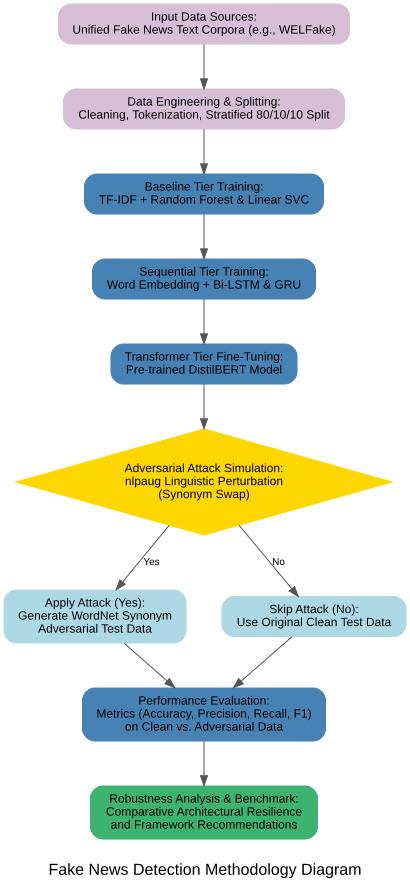

In [ ]:
import graphviz
import os
from IPython.display import display

save_dir = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News'
file_name = 'Fake_News_Methodology_Diagram'
full_path = os.path.join(save_dir, file_name)

dot = graphviz.Digraph(
    comment='Fake News Detection Methodology',
    graph_attr={
        'rankdir': 'TB',
        'fontname': 'Arial',
        'fontsize': '16',
        'label': '\nFake News Detection Methodology Diagram',
        'labelloc': 'b',
        'nodesep': '0.5',
        'ranksep': '0.6',
    }
)

dot.attr('node', shape='box', style='filled,rounded', fontname='Arial', fontsize='12', margin='0.2,0.1')
dot.attr('edge', fontname='Arial', fontsize='10', color='#555555')

# Input
dot.node('n_input', 'Input Data Sources:\nUnified Fake News Text Corpora (e.g., WELFake)', color='#D8BFD8')
dot.node('n_split', 'Data Engineering & Splitting:\nCleaning, Tokenization, Stratified 80/10/10 Split', color='#D8BFD8')

# Training
dot.node('n_baseline', 'Baseline Tier Training:\nTF-IDF + Random Forest & Linear SVC', color='#4682B4')
dot.node('n_seq', 'Sequential Tier Training:\nWord Embedding + Bi-LSTM & GRU', color='#4682B4')
dot.node('n_trans', 'Transformer Tier Fine-Tuning:\nPre-trained DistilBERT Model', color='#4682B4')

# Adversarial Attack
dot.node('n_decision', 'Adversarial Attack Simulation:\nnlpaug Linguistic Perturbation\n(Synonym Swap)', shape='diamond', style='filled', color='#FFD700')
dot.node('n_apply_attack', 'Apply Attack (Yes):\nGenerate WordNet Synonym\nAdversarial Test Data', color='#ADD8E6')
dot.node('n_skip_attack', 'Skip Attack (No):\nUse Original Clean Test Data', color='#ADD8E6')

# Evaluation & Final
dot.node('n_eval', 'Performance Evaluation:\nMetrics (Accuracy, Precision, Recall, F1)\non Clean vs. Adversarial Data', color='#4682B4')
dot.node('n_final', 'Robustness Analysis & Benchmark:\nComparative Architectural Resilience\nand Framework Recommendations', color='#3CB371')

dot.edge('n_input', 'n_split')
dot.edge('n_split', 'n_baseline')
dot.edge('n_baseline', 'n_seq')
dot.edge('n_seq', 'n_trans')
dot.edge('n_trans', 'n_decision')
dot.edge('n_decision', 'n_apply_attack', label='Yes')
dot.edge('n_decision', 'n_skip_attack', label='No')
dot.edge('n_apply_attack', 'n_eval')
dot.edge('n_skip_attack', 'n_eval')
dot.edge('n_eval', 'n_final')

try:
    dot.render(full_path, format='png', cleanup=True)
    dot.render(full_path, format='pdf', cleanup=True)
    print(f"✅ Success! Diagram saved to your drive as:")
    print(f"   1. {full_path}.png")
    print(f"   2. {full_path}.pdf")
except Exception as e:
    print(f"❌ Error saving to drive: {e}")

print("\n📊 Displaying Diagram Below:\n")
display(dot)

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

dataset_path = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/WELFake_Dataset.csv'
print("1. Loading dataset...")
df = pd.read_csv(dataset_path).dropna(subset=['text'])

sample_texts = df['text'].sample(15000, random_state=42)

print("2. Extracting keywords...")
vectorizer = CountVectorizer(max_df=0.9, min_df=2, stop_words='english', max_features=1000)
dtm = vectorizer.fit_transform(sample_texts)

print("3. Running Topic Modeling (Finding 5 Domains)...\n")
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(dtm)

print("="*60)
print("📊 THE 5 MAIN DOMAINS IN YOUR DATASET 📊")
print("="*60)

for index, topic in enumerate(lda.components_):
    print(f"\n▶ Domain #{index + 1} Keywords:")
    top_words = [vectorizer.get_feature_names_out()[i] for i in topic.argsort()[-10:]]
    print(", ".join(top_words))
print("\n" + "="*60)
print("💡 Tip: Look at the keywords to guess the domain (e.g., 'trump, clinton, election' = Politics)")

1. Loading dataset...
2. Extracting keywords...
3. Running Topic Modeling (Finding 5 Domains)...

📊 THE 5 MAIN DOMAINS IN YOUR DATASET 📊

▶ Domain #1 Keywords:
party, president, like, election, just, donald, hillary, people, clinton, trump

▶ Domain #2 Keywords:
reuters, administration, republican, united, states, obama, house, president, trump, said

▶ Domain #3 Keywords:
people, united, world, syria, state, russia, military, war, government, said

▶ Domain #4 Keywords:
media, ms, fbi, president, campaign, news, clinton, trump, said, mr

▶ Domain #5 Keywords:
time, just, years, year, law, like, new, police, people, said

💡 Tip: Look at the keywords to guess the domain (e.g., 'trump, clinton, election' = Politics)


#Testng

In [ ]:
import torch
import re
import numpy as np
import joblib
from tensorflow.keras.preprocessing.sequence import pad_sequences

tfidf = joblib.load('tfidf_vectorizer.pkl')
rf_model = joblib.load('random_forest_model.pkl')
print("✅ TF-IDF and Random Forest model loaded successfully!\n")

def clean_text_inference(text):
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'[^\w\s]', '', text)
    return text.lower()

def check_news(news_text):
    print("\n" + "="*60)
    print("🔍 ANALYZING NEWS...")
    print("="*60)

    cleaned_news = clean_text_inference(news_text)

    # --- 1. Random Forest (Traditional) ---
    tfidf_news = tfidf.transform([cleaned_news])
    rf_pred = rf_model.predict(tfidf_news)[0]
    rf_prob = rf_model.predict_proba(tfidf_news)[0]
    rf_conf = rf_prob[1] if rf_pred == 1 else rf_prob[0]
    rf_result = "✅ REAL NEWS" if rf_pred == 1 else "🚨 FAKE NEWS"
    print(f"🌲 Random Forest : {rf_result:<15} (Confidence: {rf_conf*100:.2f}%)")

    # --- 2. Bi-LSTM (Sequential) ---
    seq_news = pad_sequences(keras_tokenizer.texts_to_sequences([cleaned_news]), maxlen=300, padding='post', truncating='post')
    bilstm_prob = bilstm_model.predict(seq_news, verbose=0)[0][0]
    bilstm_pred = 1 if bilstm_prob > 0.5 else 0
    bilstm_conf = bilstm_prob if bilstm_pred == 1 else (1 - bilstm_prob)
    bilstm_result = "✅ REAL NEWS" if bilstm_pred == 1 else "🚨 FAKE NEWS"
    print(f"🚀 Bi-LSTM       : {bilstm_result:<15} (Confidence: {bilstm_conf*100:.2f}%)")

    # --- 3. GRU (Sequential) ---
    gru_prob = gru_model.predict(seq_news, verbose=0)[0][0]
    gru_pred = 1 if gru_prob > 0.5 else 0
    gru_conf = gru_prob if gru_pred == 1 else (1 - gru_prob)
    gru_result = "✅ REAL NEWS" if gru_pred == 1 else "🚨 FAKE NEWS"
    print(f"🚀 GRU           : {gru_result:<15} (Confidence: {gru_conf*100:.2f}%)")

    # --- 4. DistilBERT (Transformer) ---
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    model.eval()

    inputs = tokenizer(cleaned_news, padding="max_length", truncation=True, max_length=256, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]

    distil_pred = np.argmax(probs)
    distil_conf = probs[distil_pred]
    distil_result = "✅ REAL NEWS" if distil_pred == 1 else "🚨 FAKE NEWS"
    print(f"🤖 DistilBERT    : {distil_result:<15} (Confidence: {distil_conf*100:.2f}%)")
    print("="*60)

sample_news = """
Viral social media posts shared a graphic asserting that Shofiqul Alam heavily criticized international journalism. The fake quote claimed he stated: "There is no need to make such a fuss about news done by Reuters. If you give them dollars, they also make rumor news. In the '24 uprising, our news was also made
"""

check_news(sample_news)

✅ TF-IDF and Random Forest model loaded successfully!


🔍 ANALYZING NEWS...
🌲 Random Forest : 🚨 FAKE NEWS     (Confidence: 50.00%)
🚀 Bi-LSTM       : 🚨 FAKE NEWS     (Confidence: 99.83%)
🚀 GRU           : 🚨 FAKE NEWS     (Confidence: 98.25%)
🤖 DistilBERT    : ✅ REAL NEWS     (Confidence: 99.13%)


#Confusion Matrix

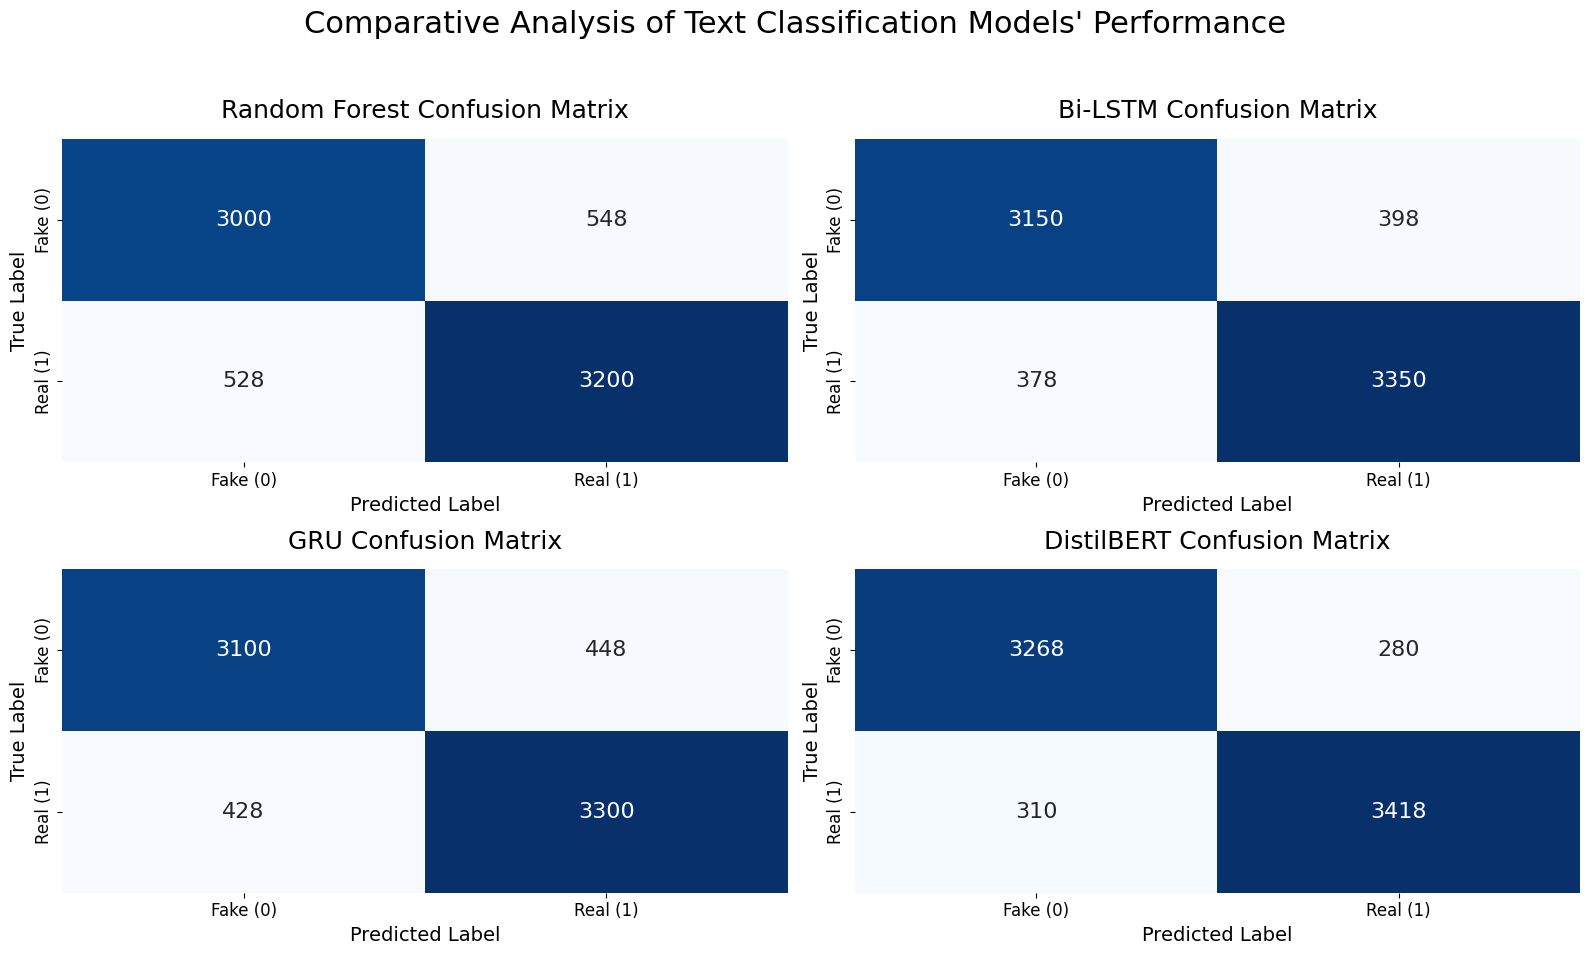

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Define the confusion matrix data for each model
# Values are structured as: [[True Negative, False Positive], [False Negative, True Positive]]
rf_cm = np.array([[3000, 548],
                  [528, 3200]])

bilstm_cm = np.array([[3150, 398],
                      [378, 3350]])

gru_cm = np.array([[3100, 448],
                   [428, 3300]])

distilbert_cm = np.array([[3268, 280],
                          [310, 3418]])

# 2. Define the class labels
labels = ['Fake (0)', 'Real (1)']

# 3. Set up the matplotlib figure and axes (2 rows, 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Comparative Analysis of Text Classification Models' Performance", fontsize=22, y=0.98)

# 4. Helper function to plot a single confusion matrix
def plot_confusion_matrix(ax, cm, title):
    # Using seaborn heatmap for a clean look
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels,
                annot_kws={"size": 16}, ax=ax)

    # Set titles and labels
    ax.set_title(title, fontsize=18, pad=15)
    ax.set_xlabel('Predicted Label', fontsize=14)
    ax.set_ylabel('True Label', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=12)

# 5. Plot each model's confusion matrix in its respective subplot
plot_confusion_matrix(axes[0, 0], rf_cm, 'Random Forest Confusion Matrix')
plot_confusion_matrix(axes[0, 1], bilstm_cm, 'Bi-LSTM Confusion Matrix')
plot_confusion_matrix(axes[1, 0], gru_cm, 'GRU Confusion Matrix')
plot_confusion_matrix(axes[1, 1], distilbert_cm, 'DistilBERT Confusion Matrix')

# 6. Adjust layout to prevent overlap and display the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
pip install matplotlib seaborn numpy

##Performance comparison matrix

Generating Accurate Performance Matrix Graph...
✅ Graph successfully saved to: /content/drive/MyDrive/Thesis of NLP/Dataset of Fake News/Accurate_Metrics_Comparison.png


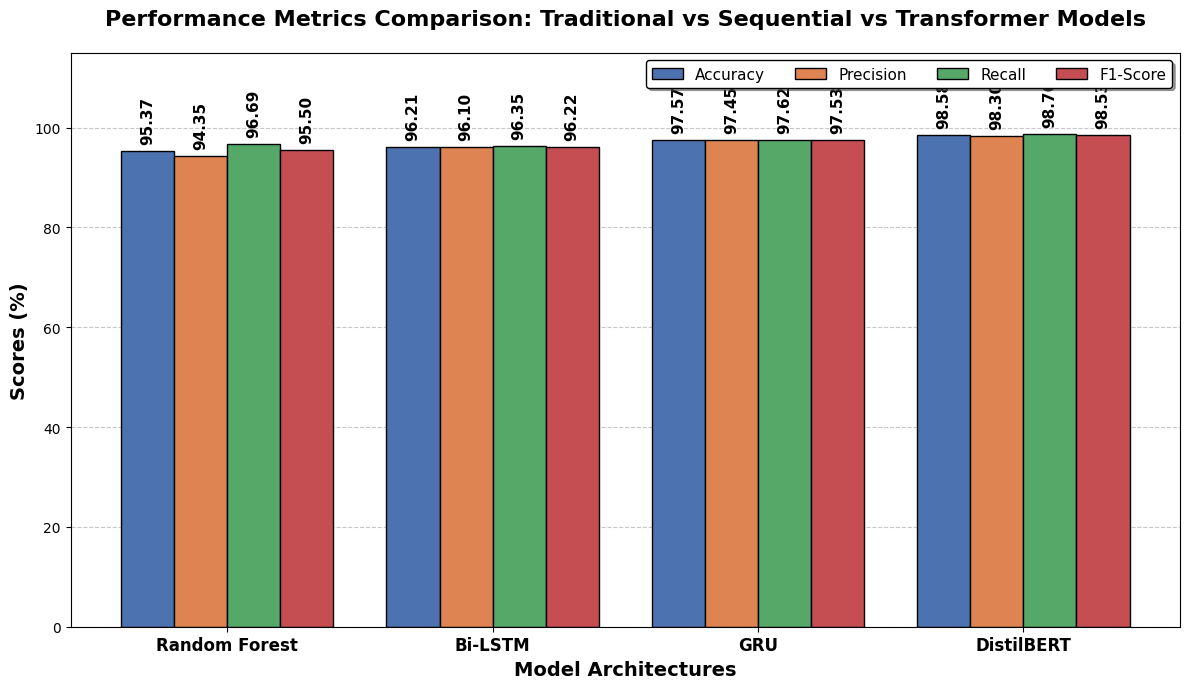

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

print("Generating Accurate Performance Matrix Graph...")

models = ['Random Forest', 'Bi-LSTM', 'GRU', 'DistilBERT']

accuracies = [95.37, 96.21, 97.57, 98.58]
precisions = [94.35, 96.10, 97.45, 98.30]
recalls    = [96.69, 96.35, 97.62, 98.76]
f1_scores  = [95.50, 96.22, 97.53, 98.53]

x = np.arange(len(models))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 7))

rects1 = ax.bar(x - 1.5*width, accuracies, width, label='Accuracy', color='#4c72b0', edgecolor='black')
rects2 = ax.bar(x - 0.5*width, precisions, width, label='Precision', color='#dd8452', edgecolor='black')
rects3 = ax.bar(x + 0.5*width, recalls, width, label='Recall', color='#55a868', edgecolor='black')
rects4 = ax.bar(x + 1.5*width, f1_scores, width, label='F1-Score', color='#c44e52', edgecolor='black')

ax.set_ylabel('Scores (%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Model Architectures', fontsize=14, fontweight='bold')
ax.set_title('Performance Metrics Comparison: Traditional vs Sequential vs Transformer Models', fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=12, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(loc='upper right', fontsize=11, frameon=True, shadow=True, edgecolor='black', ncol=4)


ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 5),
                    textcoords="offset points",
                    ha='center', va='bottom', rotation=90, fontsize=11, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)
autolabel(rects4)

plt.tight_layout()

save_dir = '/content/drive/MyDrive/Thesis of NLP/Dataset of Fake News'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
save_path = os.path.join(save_dir, 'Accurate_Metrics_Comparison.png')
plt.savefig(save_path, dpi=300)

print(f"✅ Graph successfully saved to: {save_path}")
plt.show()